# Meridian EDA

Each section states its data source: **encounters** (`meridian_health_encounters.csv`), **claims** (`data_web_claims.csv`), or **all tables**.

**Part A** — frequency of CPT and ICD-10 codes in `meridian_health_encounters.csv`
**Part B** — `patient_token` overlap across all five tables

# Part A: CPT and ICD-10 code frequency  *(source: encounters)*
`data/meridian_health_encounters.csv` — one row per clinical event.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.alpha': .25})
BLUE, ORANGE, GRAY = '#2a6fbb', '#d9822b', '#9aa0a6'   # ICD10CM, CPT, missing
SYS_COLOR = {'ICD10CM': BLUE, 'CPT': ORANGE, 'Missing': GRAY}

df = pd.read_csv('../data/meridian_health_encounters.csv', dtype=str)
df['code_system'] = df['code_system'].fillna('Missing')
print(f'{len(df):,} events, {df.event_code.nunique()} distinct codes')
df.isna().sum()

249,559 events, 23 distinct codes


patient_token          0
event_id               0
event_date             0
event_category         0
event_code          9988
code_system            0
spine_level       179570
event_status       19894
facility_id        34918
dtype: int64

## 1. Events per code category
`event_category` is the clinical category; `code_system` says whether the code is ICD-10-CM (diagnoses) or CPT (procedures). Rows with no code are shown as *Missing*.

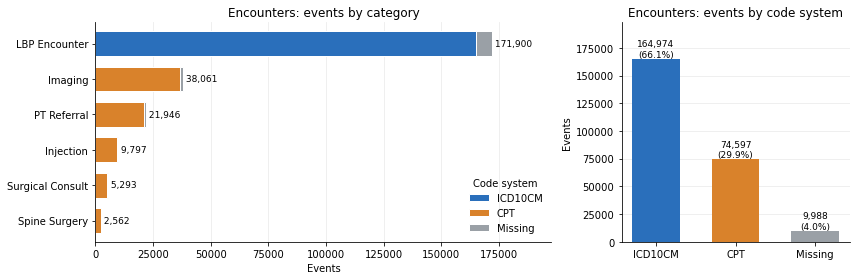

code_system,ICD10CM,CPT,Missing,total
event_category,,,,
LBP Encounter,164974,0,6926,171900
Imaging,0,36524,1537,38061
PT Referral,0,21078,868,21946
Injection,0,9432,365,9797
Surgical Consult,0,5109,184,5293
Spine Surgery,0,2454,108,2562


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [2, 1]})

# by event category, colored by code system
ct = pd.crosstab(df.event_category, df.code_system).reindex(columns=['ICD10CM', 'CPT', 'Missing'], fill_value=0)
ct = ct.loc[ct.sum(axis=1).sort_values().index]
ct.plot.barh(stacked=True, ax=axes[0], color=[SYS_COLOR[c] for c in ct.columns], width=.7, edgecolor='white')
axes[0].set(title='Encounters: events by category', xlabel='Events', ylabel='')
for y, tot in enumerate(ct.sum(axis=1)):
    axes[0].text(tot, y, f' {tot:,}', va='center', fontsize=9)
axes[0].set_xlim(0, ct.sum(axis=1).max() * 1.15)
axes[0].grid(axis='y', visible=False)
axes[0].legend(title='Code system', frameon=False, loc='lower right')

# by code system
cs = df.code_system.value_counts().reindex(['ICD10CM', 'CPT', 'Missing'])
axes[1].bar(cs.index, cs.values, color=[SYS_COLOR[c] for c in cs.index], width=.6)
for i, v in enumerate(cs.values):
    axes[1].text(i, v, f'{v:,}\n({v/len(df):.1%})', ha='center', va='bottom', fontsize=9)
axes[1].set(title='Encounters: events by code system', ylabel='Events', ylim=(0, cs.max() * 1.2))
axes[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
ct.assign(total=ct.sum(axis=1)).sort_values('total', ascending=False)

## 2. Frequency of each code
Counts per distinct code (rows with a missing code excluded; see section 1 for those).

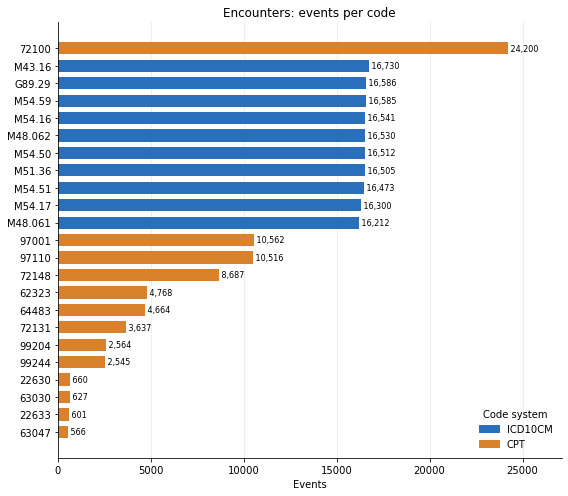

,code,system,events,Name,Description
0,72100,CPT,24200,"X-ray, lumbosacral spine, 2–3 views",Plain radiographs of the lumbar/sacral spine
1,M43.16,ICD10CM,16730,"Spondylolisthesis, lumbar region",Forward slippage of one lumbar vertebra over t...
2,G89.29,ICD10CM,16586,Other chronic pain,Chronic pain not classified elsewhere; often p...
3,M54.59,ICD10CM,16585,Other low back pain,Low back pain of a specified type not covered ...
4,M54.16,ICD10CM,16541,"Radiculopathy, lumbar region","Nerve root pain, numbness or weakness from the..."
5,M48.062,ICD10CM,16530,"Spinal stenosis, lumbar, with neurogenic claud...",Narrowed lumbar canal causing leg pain/weaknes...
6,M54.50,ICD10CM,16512,"Low back pain, unspecified",Lumbago with no further specificity
7,M51.36,ICD10CM,16505,"Other intervertebral disc degeneration, lumbar...",Degenerative disc disease of the lumbar spine
8,M54.51,ICD10CM,16473,Vertebrogenic low back pain,Back pain originating from the vertebral endpl...
9,M54.17,ICD10CM,16300,"Radiculopathy, lumbosacral region",Nerve root symptoms arising at the lumbosacral...


In [3]:
freq = (df[df.event_code.notna()].groupby(['event_code', 'code_system']).size()
        .rename('events').reset_index().sort_values('events'))
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(freq.event_code, freq.events, color=freq.code_system.map(SYS_COLOR), height=.7)
for y, v in enumerate(freq.events):
    ax.text(v, y, f' {v:,}', va='center', fontsize=8)
ax.set(title='Encounters: events per code', xlabel='Events', xlim=(0, freq.events.max() * 1.12))
ax.grid(axis='y', visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SYS_COLOR[s]) for s in ('ICD10CM', 'CPT')],
          labels=['ICD10CM', 'CPT'], title='Code system', frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

# table of the same counts, most frequent first, with code names/descriptions
code_ref = pd.read_csv('../data/cpt_icd10_codes.csv', dtype=str).rename(columns={'Code': 'code'})[['code', 'Name', 'Description']]
code_table = (freq.sort_values('events', ascending=False)
              .rename(columns={'event_code': 'code', 'code_system': 'system'})
              .merge(code_ref, on='code', how='left', validate='1:1')
              .reset_index(drop=True))
assert code_table.Name.notna().all(), 'codes missing from reference file'
code_table

## 2b. Claims: frequency of each code, patients with a surgery code  *(source: claims)*
Same view as above but from `data_web_claims.csv`. Population = every patient in the claims file (not limited to the `patients` table) who has at least one claim line for a surgery CPT code (22630, 63030, 22633 or 63047). Counts are claim lines per code across all code systems (ICD10CM, CPT, HCPCS, NDC); `patients` is the distinct patients with that code. Claim lines with a blank code system/code are excluded.

1,729 of 29,999 claims patients have a surgery code; 125,720 claim lines, 2,563 with a blank code (excluded)


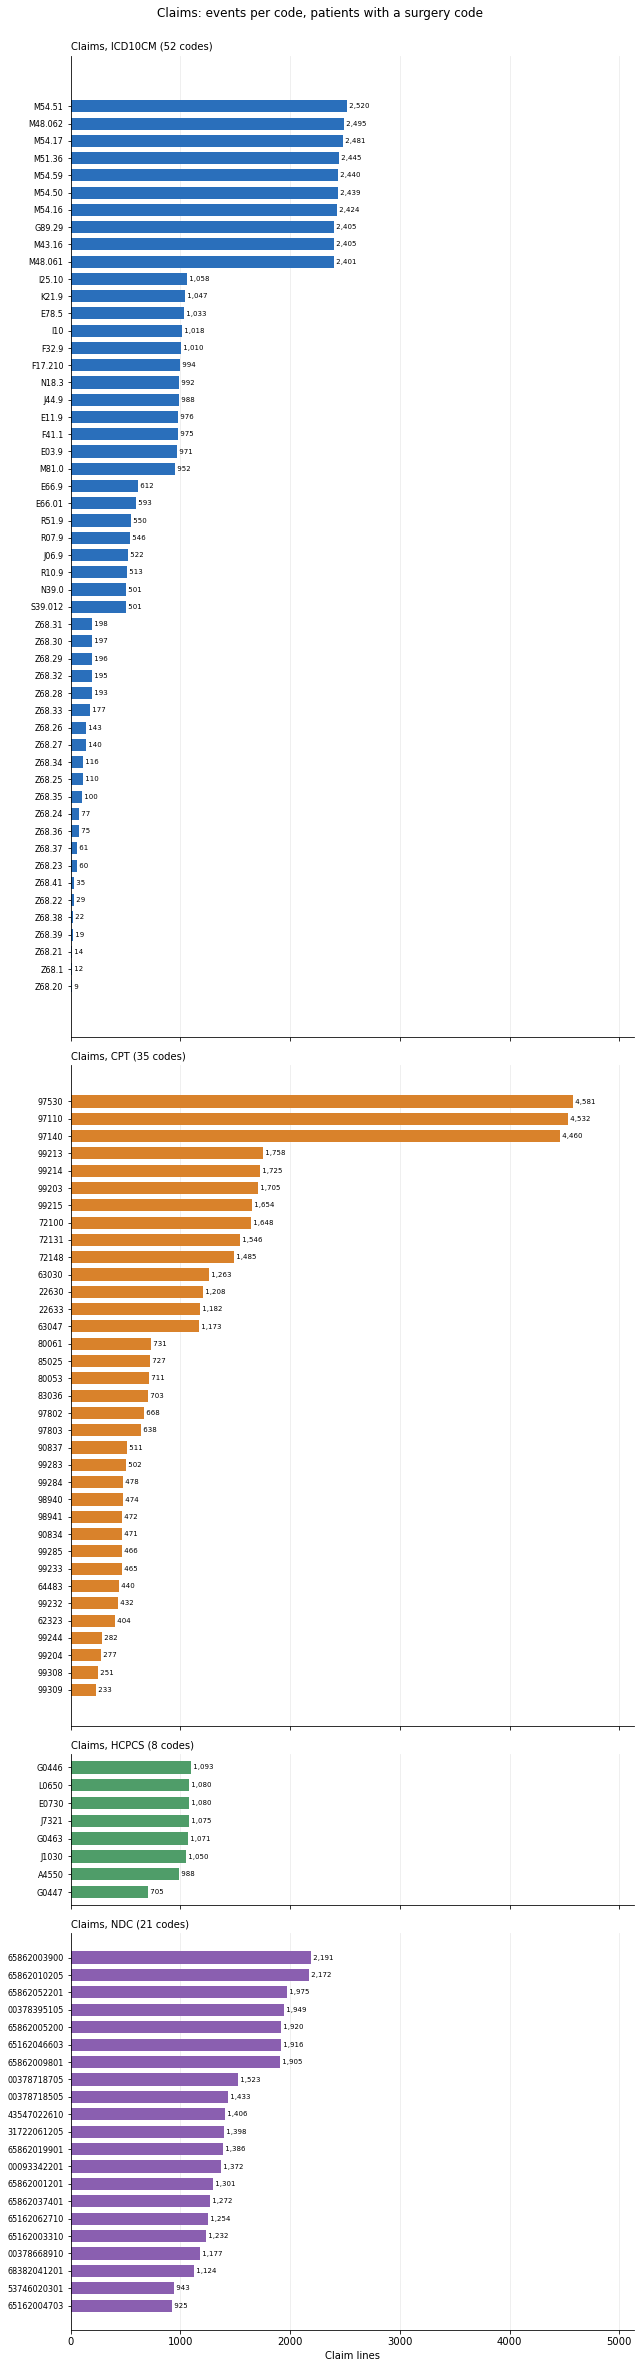

In [4]:
SURGERY_CODES = ['22630', '63030', '22633', '63047']
CLAIM_SURGERY_STATUSES = None   # e.g. ['PAID'] to require a paid surgery claim; None = any claim status

cl_all = pd.read_csv('../data/data_web_claims.csv', usecols=['patient_token', 'code_system', 'code', 'claim_status'], dtype=str)
surg_claims = cl_all[(cl_all.code_system == 'CPT') & cl_all.code.isin(SURGERY_CODES)]
if CLAIM_SURGERY_STATUSES:
    surg_claims = surg_claims[surg_claims.claim_status.isin(CLAIM_SURGERY_STATUSES)]
claims_surg_patients = set(surg_claims.patient_token)

cs_df = cl_all[cl_all.patient_token.isin(claims_surg_patients)]
print(f'{len(claims_surg_patients):,} of {cl_all.patient_token.nunique():,} claims patients have a surgery code; '
      f'{len(cs_df):,} claim lines, {(cs_df.code.isna() | cs_df.code_system.isna()).sum():,} with a blank code (excluded)')

CSYS_COLOR = {'ICD10CM': BLUE, 'CPT': ORANGE, 'HCPCS': '#4f9d69', 'NDC': '#8a5fb0'}
cfreq = (cs_df.dropna(subset=['code', 'code_system']).groupby(['code_system', 'code'])
         .agg(events=('patient_token', 'size'), patients=('patient_token', 'nunique')).reset_index())

SYSTEMS = ['ICD10CM', 'CPT', 'HCPCS', 'NDC']
panels = [cfreq[cfreq.code_system == s].sort_values('events') for s in SYSTEMS]
fig, axes = plt.subplots(len(SYSTEMS), 1, figsize=(9, 0.24 * len(cfreq) + 5), sharex=True,
                         gridspec_kw={'height_ratios': [len(p) for p in panels]})
for ax, s, p in zip(axes, SYSTEMS, panels):
    ax.barh(p.code, p.events, color=CSYS_COLOR[s], height=.7)
    for y, v in enumerate(p.events):
        ax.text(v, y, f' {v:,}', va='center', fontsize=7)
    ax.set_title(f'Claims, {s} ({len(p)} codes)', loc='left', fontsize=10)
    ax.grid(axis='y', visible=False); ax.tick_params(axis='y', labelsize=8)
axes[0].set_xlim(0, cfreq.events.max() * 1.12)
axes[-1].set_xlabel('Claim lines')
fig.suptitle('Claims: events per code, patients with a surgery code', y=1.0)
plt.tight_layout(); plt.show()

In [5]:
# table of the same counts, most frequent first (names/descriptions available for the 23 codes in the encounters reference file)
claims_code_table = (cfreq.sort_values('events', ascending=False)
                     .rename(columns={'code_system': 'system'})
                     .merge(code_ref, on='code', how='left')
                     .reset_index(drop=True))
claims_code_table

,system,code,events,patients,Name,Description
0,CPT,97530,4581,928,NaN,NaN
1,CPT,97110,4532,926,"Therapeutic exercise, each 15 min","Exercises for strength, endurance, range of mo..."
2,CPT,97140,4460,921,NaN,NaN
3,ICD10CM,M54.51,2520,1159,Vertebrogenic low back pain,Back pain originating from the vertebral endpl...
4,ICD10CM,M48.062,2495,1175,"Spinal stenosis, lumbar, with neurogenic claud...",Narrowed lumbar canal causing leg pain/weaknes...
...,...,...,...,...,...,...
111,ICD10CM,Z68.38,22,12,NaN,NaN
112,ICD10CM,Z68.39,19,10,NaN,NaN
113,ICD10CM,Z68.21,14,8,NaN,NaN
114,ICD10CM,Z68.1,12,6,NaN,NaN


## 3. Histogram of code frequency
Each observation is one distinct code; the x-axis is how many events use it. Shows whether code usage is balanced or dominated by a few codes.

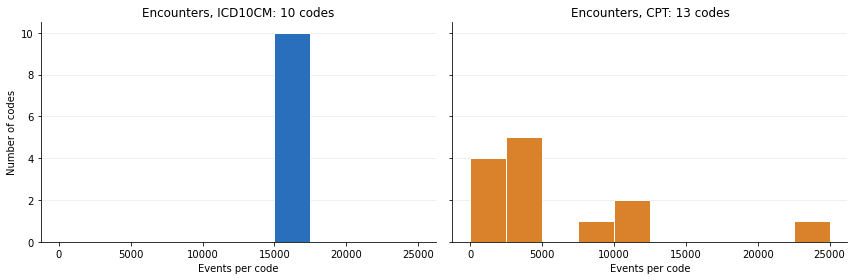

,count,mean,std,min,25%,50%,75%,max
code_system,,,,,,,,
CPT,13.0,5738.0,6630.0,566.0,660.0,3637.0,8687.0,24200.0
ICD10CM,10.0,16497.0,147.0,16212.0,16481.0,16521.0,16574.0,16730.0


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = range(0, int(freq.events.max()) + 2500, 2500)
for a, s in zip(ax, ['ICD10CM', 'CPT']):
    sub = freq[freq.code_system == s]
    a.hist(sub.events, bins=bins, color=SYS_COLOR[s], edgecolor='white')
    a.set(title=f'Encounters, {s}: {len(sub)} codes', xlabel='Events per code')
    a.grid(axis='x', visible=False)
ax[0].set_ylabel('Number of codes')
plt.tight_layout(); plt.show()
freq.groupby('code_system').events.describe().round(0)

# Part B: `patient_token` overlap across tables  *(source: all five tables)*
How many patients appear in each table, and how many are shared between each pair of tables?

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FILES = {
    'patients':    'meridian_health_patients.csv',
    'encounters':  'meridian_health_encounters.csv',
    'enrollments': 'meridian_health_enrollments.csv',
    'outreach':    'meridian_health_outreach.csv',
    'claims':      'data_web_claims.csv',
}
tokens = {}
for name, f in FILES.items():
    s = pd.read_csv(f'../data/{f}', usecols=['patient_token'], dtype=str)['patient_token']
    print(f'{name:12s} rows={len(s):>9,}  null={s.isna().sum():>5,}  distinct={s.nunique():>7,}  '
          f'whitespace/uppercase variants={(s.dropna() != s.dropna().str.strip().str.lower()).sum()}')
    tokens[name] = set(s.dropna())

patients     rows=   30,000  null=    0  distinct= 30,000  whitespace/uppercase variants=0
encounters   rows=  249,559  null=    0  distinct= 28,067  whitespace/uppercase variants=0
enrollments  rows=   22,345  null=    0  distinct= 10,042  whitespace/uppercase variants=0
outreach     rows=   38,464  null=    0  distinct= 11,075  whitespace/uppercase variants=0
claims       rows=1,752,450  null=    0  distinct= 29,999  whitespace/uppercase variants=0


## Overlap matrix (counts)
Cell *(row, col)* = number of distinct patients present in both tables. The diagonal is each table's distinct patient count.

In [8]:
names = list(FILES)
counts = pd.DataFrame([[len(tokens[a] & tokens[b]) for b in names] for a in names], index=names, columns=names)
counts

,patients,encounters,enrollments,outreach,claims
patients,30000,28067,10042,11075,29999
encounters,28067,28067,10042,11075,28066
enrollments,10042,10042,10042,5785,10042
outreach,11075,11075,5785,11075,11075
claims,29999,28066,10042,11075,29999


## Overlap matrix (% of row table's patients found in column table)
Asymmetric: read across a row. E.g. row *encounters*, column *patients* = share of patients with encounters who exist in the patients table.

In [9]:
pct = counts.div(np.diag(counts), axis=0)
pct.style.format('{:.1%}').background_gradient(cmap='Blues', vmin=0, vmax=1)

,patients,encounters,enrollments,outreach,claims
patients,100.0%,93.6%,33.5%,36.9%,100.0%
encounters,100.0%,100.0%,35.8%,39.5%,100.0%
enrollments,100.0%,100.0%,100.0%,57.6%,100.0%
outreach,100.0%,100.0%,52.2%,100.0%,100.0%
claims,100.0%,93.6%,33.5%,36.9%,100.0%


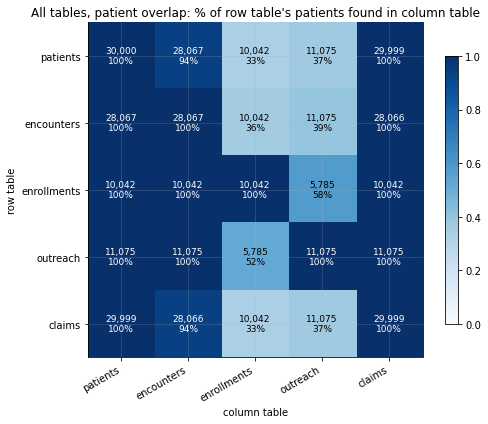

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(pct.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=30, ha='right'); ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f'{counts.iat[i, j]:,}\n{pct.iat[i, j]:.0%}', ha='center', va='center', fontsize=9,
                color='white' if pct.iat[i, j] > .6 else 'black')
ax.set(title="All tables, patient overlap: % of row table's patients found in column table", xlabel='column table', ylabel='row table')
plt.colorbar(im, shrink=.8); plt.tight_layout(); plt.show()

## Patients not in the `patients` table (orphans)

In [11]:
pd.Series({n: len(tokens[n] - tokens['patients']) for n in names if n != 'patients'}, name='tokens missing from patients')

encounters     0
enrollments    0
outreach       0
claims         0
Name: tokens missing from patients, dtype: int64

# Part C: Rows per patient, by table  *(source: each table as labeled)*
Restricted to patients in the `patients` table (all 30,000). Patients with no rows in a table are counted as **0**, so the zero bar shows how many patients are absent from that table. `patients` itself has one row per patient by construction, so it is omitted.

In [12]:
patient_ids = pd.Index(sorted(tokens['patients']))
rows_per_patient = {}
for name, f in FILES.items():
    if name == 'patients':
        continue
    s = pd.read_csv(f'../data/{f}', usecols=['patient_token'], dtype=str)['patient_token']
    rows_per_patient[name] = s[s.isin(tokens['patients'])].value_counts().reindex(patient_ids, fill_value=0)
rpp = pd.DataFrame(rows_per_patient)
rpp.describe(percentiles=[.25, .5, .75, .95]).round(1)

,encounters,enrollments,outreach,claims
count,30000.0,30000.0,30000.0,30000.0
mean,8.3,0.7,1.3,58.4
std,4.7,1.3,1.9,32.6
min,0.0,0.0,0.0,0.0
25%,5.0,0.0,0.0,37.0
50%,9.0,0.0,0.0,53.0
75%,12.0,1.0,3.0,75.0
95%,16.0,4.0,5.0,119.0
max,28.0,7.0,9.0,321.0


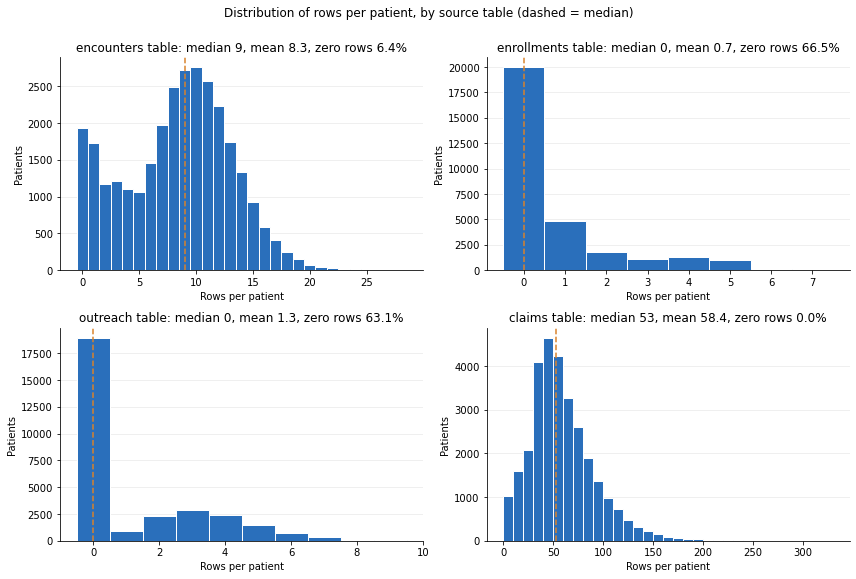

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, name in zip(axes.flat, rpp.columns):
    s = rpp[name]
    step = 10 if s.max() > 40 else 1
    bins = np.arange(0, s.max() + step + 1, step) - (0.5 if step == 1 else 0)
    ax.hist(s, bins=bins, color='#2a6fbb', edgecolor='white')
    ax.axvline(s.median(), color='#d9822b', lw=1.5, ls='--')
    ax.set(title=f'{name} table: median {s.median():.0f}, mean {s.mean():.1f}, zero rows {(s == 0).mean():.1%}',
           xlabel='Rows per patient', ylabel='Patients')
    ax.grid(axis='x', visible=False)
fig.suptitle('Distribution of rows per patient, by source table (dashed = median)', y=1.0)
plt.tight_layout(); plt.show()

# Part D: Time span per patient, by table  *(source: each table as labeled)*
For each patient: days from their first to last row in a table (`max(date) - min(date)`). Restricted to patients in the `patients` table. Patients with a single row have a span of 0 by construction, so spans are shown for patients with **2+ rows** only. `patients` is represented by its coverage window (`coverage_start` to `coverage_end`).

In [14]:
DATE_COL = {'encounters': 'event_date', 'enrollments': 'enrollment_date',
            'outreach': 'timestamp', 'claims': 'service_date'}
spans, n_bad = {}, {}
for name, col in DATE_COL.items():
    d = pd.read_csv(f'../data/{FILES[name]}', usecols=['patient_token', col], dtype=str)
    d = d[d.patient_token.isin(tokens['patients'])]
    d[col] = pd.to_datetime(d[col], errors='coerce')
    n_bad[name] = d[col].isna().sum()
    g = d.dropna(subset=[col]).groupby('patient_token')[col]
    spans[name] = pd.DataFrame({'n': g.size(), 'span_days': (g.max() - g.min()).dt.days})

pat = pd.read_csv('../data/meridian_health_patients.csv', usecols=['patient_token', 'coverage_start', 'coverage_end'],
                  parse_dates=['coverage_start', 'coverage_end']).set_index('patient_token')
print('unparseable dates:', n_bad, '| patients with no coverage_end:', pat.coverage_end.isna().sum())
cov = (pat.coverage_end - pat.coverage_start).dt.days.dropna()

summary = pd.concat({k: v.span_days[v.n >= 2] for k, v in spans.items()} | {'coverage (patients)': cov}, axis=1)
summary.describe(percentiles=[.25, .5, .75, .95]).round(1).T.assign(
    patients_with_1_row=pd.Series({k: (v.n == 1).sum() for k, v in spans.items()}))

unparseable dates: {'encounters': 0, 'enrollments': 0, 'outreach': 0, 'claims': 0} | patients with no coverage_end: 22200


,count,mean,std,min,25%,50%,75%,95%,max,patients_with_1_row
encounters,26337.0,536.8,232.6,0.0,393.0,521.0,718.0,901.0,1090.0,1730.0
enrollments,5219.0,531.2,213.0,13.0,372.0,567.0,716.5,832.0,1042.0,4823.0
outreach,10147.0,9.8,7.0,0.0,4.0,8.0,14.0,23.0,47.0,928.0
claims,29994.0,1026.8,88.3,56.0,1016.0,1053.0,1074.0,1088.0,1095.0,5.0
coverage (patients),7800.0,704.5,258.8,45.0,499.0,730.0,933.0,1062.0,1094.0,NaN


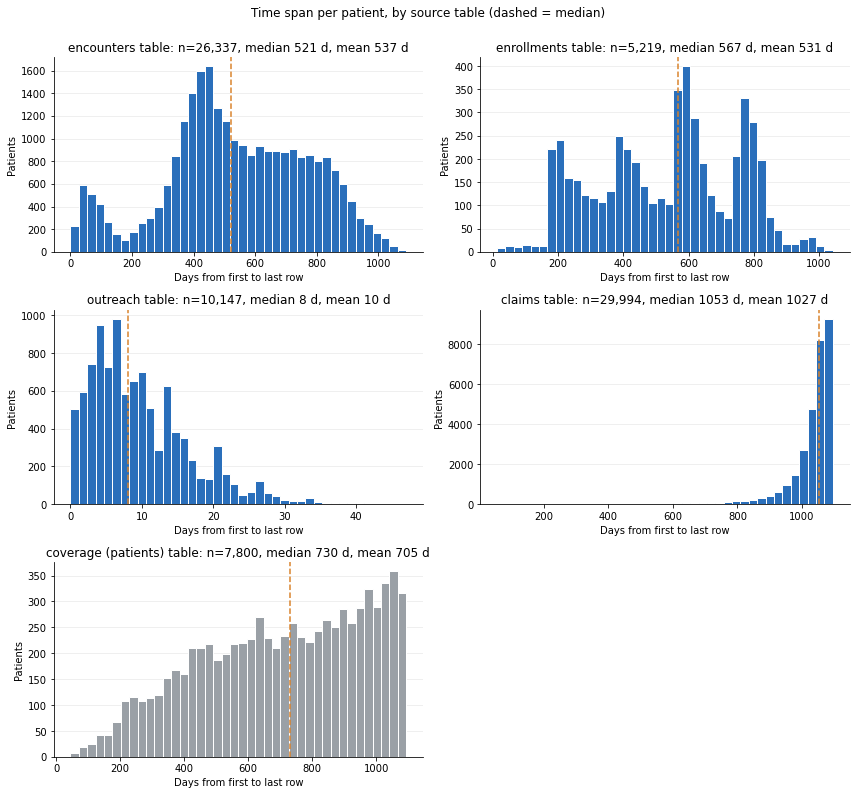

In [15]:
series = {k: v.span_days[v.n >= 2] for k, v in spans.items()} | {'coverage (patients)': cov}
fig, axes = plt.subplots(3, 2, figsize=(12, 11))
for ax, (name, s) in zip(axes.flat, series.items()):
    ax.hist(s, bins=40, color='#2a6fbb' if 'coverage' not in name else GRAY, edgecolor='white')
    ax.axvline(s.median(), color='#d9822b', lw=1.5, ls='--')
    ax.set(title=f'{name} table: n={len(s):,}, median {s.median():.0f} d, mean {s.mean():.0f} d',
           xlabel='Days from first to last row', ylabel='Patients')
    ax.grid(axis='x', visible=False)
axes.flat[-1].axis('off')
fig.suptitle('Time span per patient, by source table (dashed = median)', y=1.0)
plt.tight_layout(); plt.show()

# Part E: Time from first code to first surgery  *(source: encounters codes and surgery)*
For each patient, **first surgery** = earliest `event_date` of a surgery row (CPT 22630, 63030, 22633 or 63047). For every code, the first date it appears for that patient (any status) is compared to that surgery date: `days = first surgery − first code`. Positive = code appeared before surgery; negative = the code first appeared after surgery.

Only surgeries with a status in `SURGERY_STATUSES` count. Default is `Performed` — cancelled, no-show and scheduled surgeries did not (yet) happen. Change the list below to explore other definitions (rows with a missing status are otherwise excluded).

In [16]:
SURGERY_CODES = ['22630', '63030', '22633', '63047']
SURGERY_STATUSES = ['Performed']

enc = pd.read_csv('../data/meridian_health_encounters.csv', dtype=str, parse_dates=['event_date'])
enc = enc[enc.patient_token.isin(tokens['patients']) & enc.event_code.notna()]

first_surgery = (enc[enc.event_code.isin(SURGERY_CODES) & enc.event_status.isin(SURGERY_STATUSES)]
                 .groupby('patient_token').event_date.min().rename('first_surgery'))
first_code = enc.groupby(['patient_token', 'event_code']).event_date.min().rename('first_code').reset_index()
t = first_code.merge(first_surgery, on='patient_token')          # only patients with a surgery
t['days_to_surgery'] = (t.first_surgery - t.first_code).dt.days
print(f'{len(first_surgery):,} patients with a surgery ({", ".join(SURGERY_STATUSES)})')

t['after'] = t.days_to_surgery < 0
matrix = (t.groupby('event_code').agg(patients=('days_to_surgery', 'size'), mean_days=('days_to_surgery', 'mean'),
                                      median_days=('days_to_surgery', 'median'),
                                      p25=('days_to_surgery', lambda d: d.quantile(.25)),
                                      p75=('days_to_surgery', lambda d: d.quantile(.75)),
                                      pct_first_after_surgery=('after', 'mean'))
          .reset_index().rename(columns={'event_code': 'code'})
          .merge(code_table[['code', 'system', 'Name']], on='code', how='left')
          .sort_values('median_days', ascending=False).reset_index(drop=True))
matrix['pct_first_after_surgery'] *= 100
matrix = matrix[['code', 'system', 'Name', 'patients', 'mean_days', 'median_days', 'p25', 'p75', 'pct_first_after_surgery']]
matrix.round(1)

1,951 patients with a surgery (Performed)


,code,system,Name,patients,mean_days,median_days,p25,p75,pct_first_after_surgery
0,99244,CPT,"Office consultation, moderate complexity",423,157.8,170.0,74.5,269.0,10.9
1,99204,CPT,"New patient office visit, moderate complexity",407,148.1,148.0,57.0,253.0,11.3
2,M43.16,ICD10CM,"Spondylolisthesis, lumbar region",795,19.1,72.0,-172.0,217.5,40.5
3,M48.062,ICD10CM,"Spinal stenosis, lumbar, with neurogenic claud...",810,27.9,66.5,-157.0,209.5,40.7
4,M54.17,ICD10CM,"Radiculopathy, lumbosacral region",790,15.0,64.5,-181.0,209.5,42.8
5,M54.59,ICD10CM,Other low back pain,789,13.1,61.0,-172.0,210.0,41.3
6,M54.16,ICD10CM,"Radiculopathy, lumbar region",785,10.9,54.0,-183.0,209.0,43.3
7,M54.50,ICD10CM,"Low back pain, unspecified",804,15.2,53.0,-174.5,219.0,42.7
8,M51.36,ICD10CM,"Other intervertebral disc degeneration, lumbar...",793,0.8,51.0,-201.0,208.0,43.9
9,M54.51,ICD10CM,Vertebrogenic low back pain,777,12.1,49.0,-175.0,214.0,43.0


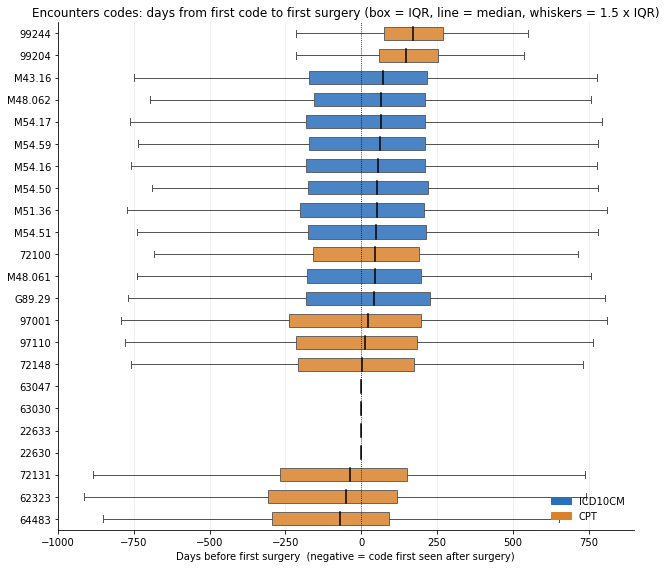

In [17]:
order = matrix.code[::-1].tolist()                       # highest median at top
system = matrix.set_index('code').system
data = [t.loc[t.event_code == k, 'days_to_surgery'] for k in order]
fig, ax = plt.subplots(figsize=(9, 8))
bp = ax.boxplot(data, vert=False, labels=order, patch_artist=True, showfliers=False, widths=.6,
                medianprops=dict(color='black', lw=1.5), whiskerprops=dict(color='#555'), capprops=dict(color='#555'))
for patch, k in zip(bp['boxes'], order):
    patch.set(facecolor=SYS_COLOR[system[k]], alpha=.85, edgecolor='#555')
ax.axvline(0, color='black', lw=.8, ls=':')
ax.set(title='Encounters codes: days from first code to first surgery (box = IQR, line = median, whiskers = 1.5 x IQR)',
       xlabel='Days before first surgery  (negative = code first seen after surgery)')
ax.grid(axis='y', visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SYS_COLOR[s]) for s in ('ICD10CM', 'CPT')],
          labels=['ICD10CM', 'CPT'], frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

# Part F: Patients with surgery (groundwork for splits)  *(source: encounters)*
How many patients have a surgery in the encounters table? "Surgery" can be defined several ways, so the count is shown for each definition: by `event_category == 'Spine Surgery'`, by the four surgery CPT codes, and by event status.

In [18]:
enc_all = pd.read_csv('../data/meridian_health_encounters.csv', dtype=str, parse_dates=['event_date'])
enc_all = enc_all[enc_all.patient_token.isin(tokens['patients'])]
enc_all['event_status'] = enc_all.event_status.fillna('Missing')

surg = enc_all[(enc_all.event_category == 'Spine Surgery') | enc_all.event_code.isin(SURGERY_CODES)]
print('rows by category x code-is-surgery-code:')
print(pd.crosstab(surg.event_category, surg.event_code.isin(SURGERY_CODES).map({True: 'surgery code', False: 'other/missing code'})))

n_pat = len(tokens['patients'])
defs = {
    'Spine Surgery category, any status': surg,
    'Surgery code (4 CPTs), any status': surg[surg.event_code.isin(SURGERY_CODES)],
    'Surgery code, status = Performed': surg[surg.event_code.isin(SURGERY_CODES) & (surg.event_status == 'Performed')],
}
pd.DataFrame({k: {'patients': v.patient_token.nunique(), 'rows': len(v)} for k, v in defs.items()}).T.assign(
    pct_of_all_patients=lambda d: (d.patients / n_pat * 100).round(1))

rows by category x code-is-surgery-code:
event_code      other/missing code  surgery code
event_category                                  
Spine Surgery                  108          2454


,patients,rows,pct_of_all_patients
"Spine Surgery category, any status",2556,2562,8.5
"Surgery code (4 CPTs), any status",2449,2454,8.2
"Surgery code, status = Performed",1951,1951,6.5


### Surgery rows by status and code

In [19]:
sc = surg[surg.event_code.isin(SURGERY_CODES)]
by_status = (sc.groupby('event_status').agg(rows=('event_id', 'size'), patients=('patient_token', 'nunique'))
             .sort_values('rows', ascending=False))
display(by_status)
display(pd.crosstab(sc.event_code, sc.event_status, margins=True))

,rows,patients
event_status,,
Performed,1951,1951
Missing,224,224
Scheduled,142,142
Cancelled,95,95
No Show,42,42


event_status,Cancelled,Missing,No Show,Performed,Scheduled,All
event_code,,,,,,
22630,20,59,8,532,41,660
22633,30,58,9,475,29,601
63030,28,57,16,488,38,627
63047,17,50,9,456,34,566
All,95,224,42,1951,142,2454


### Surgeries per patient and timing (Performed surgeries)

,patients
performed surgeries,
1,1951


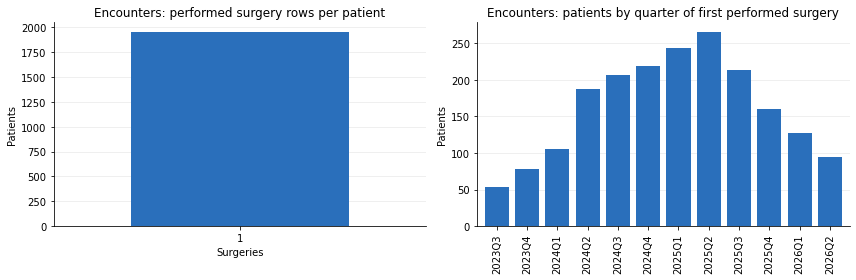

1,951 patients with a performed surgery of 30,000 (6.5%)


In [20]:
perf = sc[sc.event_status == 'Performed']
per_pat = perf.groupby('patient_token').agg(surgeries=('event_id', 'size'), first_surgery=('event_date', 'min'))
display(per_pat.surgeries.value_counts().sort_index().rename('patients').to_frame('patients').rename_axis('performed surgeries'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
per_pat.surgeries.value_counts().sort_index().plot.bar(ax=ax[0], color=BLUE, width=.7, rot=0)
ax[0].set(title='Encounters: performed surgery rows per patient', xlabel='Surgeries', ylabel='Patients'); ax[0].grid(axis='x', visible=False)
per_pat.first_surgery.dt.to_period('Q').value_counts().sort_index().plot.bar(ax=ax[1], color=BLUE, width=.8)
ax[1].set(title='Encounters: patients by quarter of first performed surgery', xlabel='', ylabel='Patients'); ax[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
print(f'{len(per_pat):,} patients with a performed surgery of {n_pat:,} ({len(per_pat)/n_pat:.1%})')

# Part G: Time from first claim code to first surgery (all codes in the claims feed)  *(source: claims codes, encounters surgery)*
Same calculation as Part E, but the codes come from `data_web_claims.csv` — **every code in every `code_system`** (ICD10CM, CPT, HCPCS, NDC) — and the date is `service_date`. The anchor is still the **first performed surgery from the encounters table** (`first_surgery`, Part E). Positive days = the code's first claim was before surgery. Claim lines with a blank `code_system`/`code` (about 35k) are dropped. Claims with any `claim_status` count unless you restrict `CLAIM_STATUSES`.

In [21]:
CLAIM_STATUSES = None   # e.g. ['PAID'] to keep only paid claim lines; None = all statuses

cl = pd.read_csv('../data/data_web_claims.csv', usecols=['patient_token', 'service_date', 'code_system', 'code', 'claim_status'],
                 dtype=str, parse_dates=['service_date'])
cl = cl[cl.code.notna() & cl.code_system.notna() & cl.patient_token.isin(first_surgery.index)]
if CLAIM_STATUSES:
    cl = cl[cl.claim_status.isin(CLAIM_STATUSES)]

tc = (cl.groupby(['patient_token', 'code_system', 'code']).service_date.min().rename('first_code').reset_index()
        .merge(first_surgery, on='patient_token'))
tc['days_to_surgery'] = (tc.first_surgery - tc.first_code).dt.days
tc['after'] = tc.days_to_surgery < 0
claims_matrix = (tc.groupby(['code_system', 'code']).agg(patients=('days_to_surgery', 'size'), mean_days=('days_to_surgery', 'mean'),
                                        median_days=('days_to_surgery', 'median'),
                                        p25=('days_to_surgery', lambda d: d.quantile(.25)),
                                        p75=('days_to_surgery', lambda d: d.quantile(.75)),
                                        pct_first_after_surgery=('after', 'mean'))
                 .reset_index().sort_values(['code_system', 'median_days'], ascending=[True, False]).reset_index(drop=True))
claims_matrix['pct_first_after_surgery'] *= 100
print(f'{tc.patient_token.nunique():,} surgery patients with claims; codes per system:', claims_matrix.code_system.value_counts().to_dict())
claims_matrix.round(1)

1,951 surgery patients with claims; codes per system: {'ICD10CM': 52, 'CPT': 35, 'NDC': 21, 'HCPCS': 8}


,code_system,code,patients,mean_days,median_days,p25,p75,pct_first_after_surgery
0,CPT,99215,1019,149.1,177.0,-129.0,446.0,34.7
1,CPT,99214,1015,150.4,166.0,-143.0,462.5,36.1
2,CPT,85025,568,124.6,161.0,-161.2,400.2,38.6
3,CPT,99203,1033,141.6,160.0,-136.0,428.0,36.0
4,CPT,99244,288,143.1,159.0,68.8,252.2,11.5
...,...,...,...,...,...,...,...,...
111,NDC,65162062710,834,76.4,85.0,-147.8,266.0,40.3
112,NDC,65162003310,821,73.5,75.0,-127.0,254.0,37.8
113,NDC,31722061205,872,68.1,71.5,-137.0,246.0,40.9
114,NDC,65162004703,637,63.0,67.0,-151.0,235.0,40.5


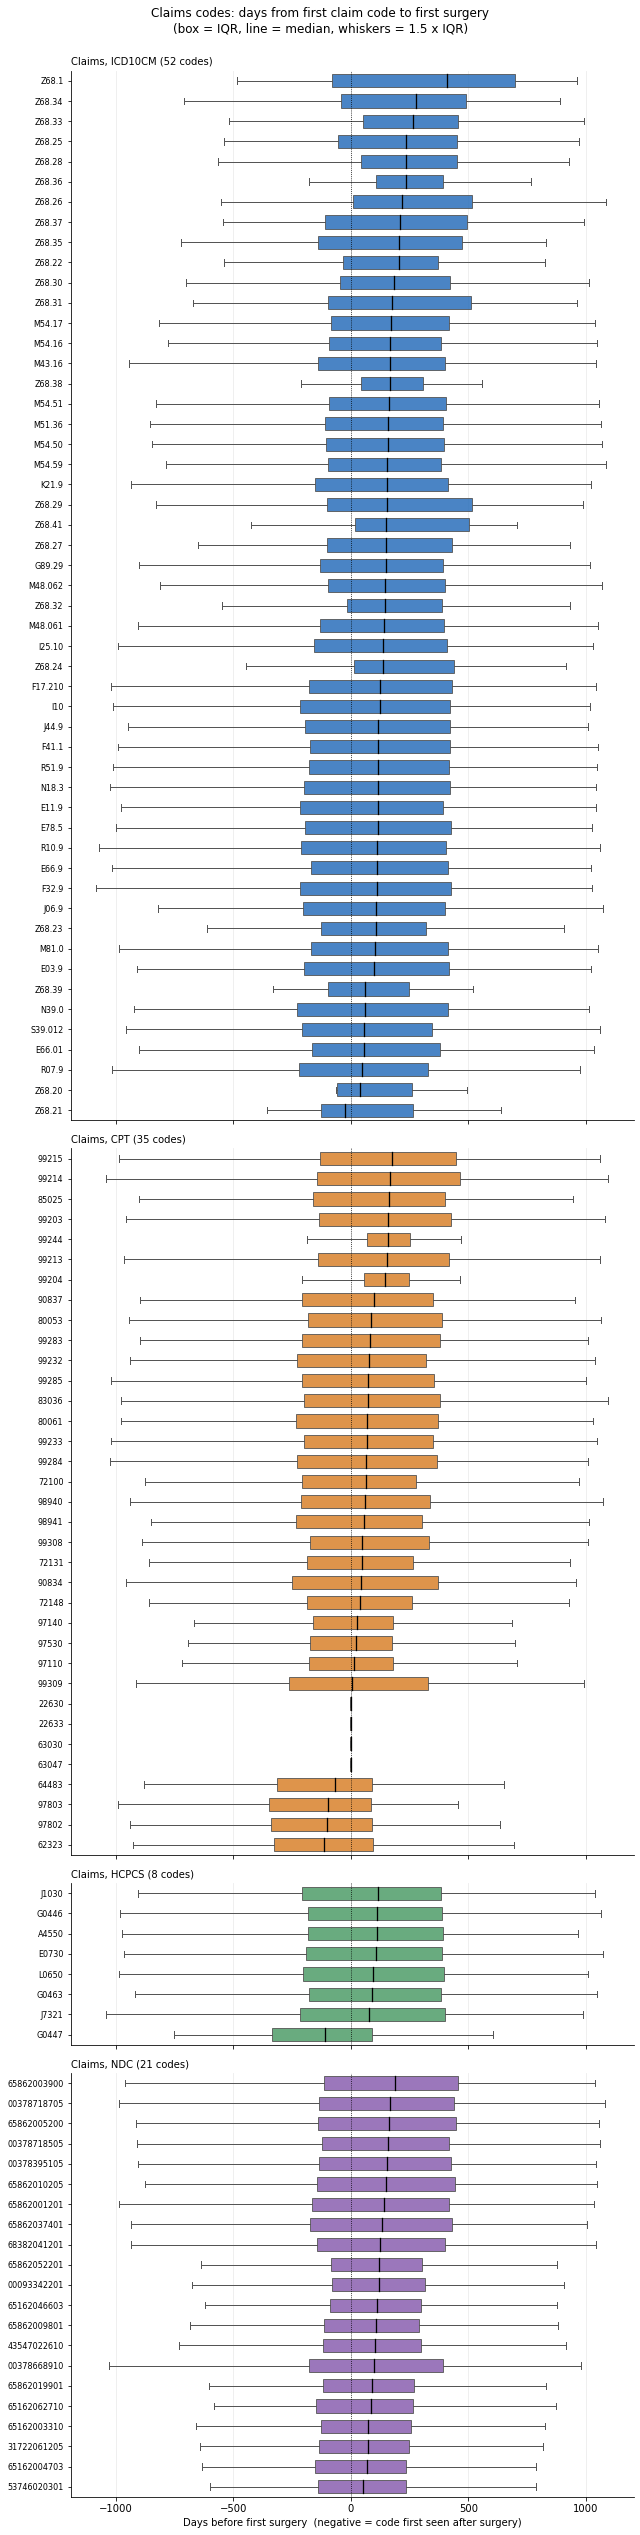

In [22]:
SYSTEMS = ['ICD10CM', 'CPT', 'HCPCS', 'NDC']
counts = [(claims_matrix.code_system == s).sum() for s in SYSTEMS]
fig, axes = plt.subplots(len(SYSTEMS), 1, figsize=(9, 0.26 * sum(counts) + 5), sharex=True,
                         gridspec_kw={'height_ratios': counts})
for ax, s in zip(axes, SYSTEMS):
    order = claims_matrix[claims_matrix.code_system == s].sort_values('median_days').code.tolist()   # highest median at top
    data = [tc.loc[(tc.code_system == s) & (tc.code == k), 'days_to_surgery'] for k in order]
    bp = ax.boxplot(data, vert=False, labels=order, patch_artist=True, showfliers=False, widths=.65,
                    medianprops=dict(color='black', lw=1.3), whiskerprops=dict(color='#555'), capprops=dict(color='#555'))
    for patch in bp['boxes']:
        patch.set(facecolor=SYS_COLOR.get(s, GRAY) if s != 'HCPCS' and s != 'NDC' else {'HCPCS': '#4f9d69', 'NDC': '#8a5fb0'}[s],
                  alpha=.85, edgecolor='#555')
    ax.axvline(0, color='black', lw=.8, ls=':')
    ax.set_title(f'Claims, {s} ({len(order)} codes)', loc='left', fontsize=10)
    ax.grid(axis='y', visible=False); ax.tick_params(axis='y', labelsize=8)
axes[-1].set_xlabel('Days before first surgery  (negative = code first seen after surgery)')
fig.suptitle('Claims codes: days from first claim code to first surgery\n(box = IQR, line = median, whiskers = 1.5 x IQR)', y=1.0)
plt.tight_layout(); plt.show()

# Part H: Patient pathway timing  *(sources: patients, encounters, claims)*

This section translates the stated pathway into six observed milestones: **earliest record → imaging → referred → injections → see surgeon → surgery**. Clinical milestones use the curated `event_category` in the orthopedic encounters extract and the first **Performed** event in each category. `Earliest record` is the earliest of coverage start, any encounter, or any claim, so it measures from the first observable date rather than assuming the first low-back-pain diagnosis is the start of illness.

Each matrix cell is read **row → column** and summarizes `first column event − first row event`, in days, among patients observed at both milestones. Negative values are retained: they reveal out-of-order pathways or incomplete history rather than being silently discarded. `n` is cell-specific because later milestones occur in progressively smaller cohorts. These are descriptive elapsed times, not causal estimates; first-record gaps can be left-truncated by the 2023-07-01 extract boundary.

In [23]:
STAGES = ['Earliest record', 'Imaging', 'Referred', 'Injections', 'See surgeon', 'Surgery']
CATEGORY_TO_STAGE = {
    'LBP Encounter': 'Earliest record',
    'Imaging': 'Imaging',
    'PT Referral': 'Referred',
    'Injection': 'Injections',
    'Surgical Consult': 'See surgeon',
    'Spine Surgery': 'Surgery',
}

# The taxonomy is intentionally derived from the curated encounters source. Codes such as
# 99204 are nonspecific in general claims, but are spine-relevant inside this extract.
enc_path = pd.read_csv('../data/meridian_health_encounters.csv', dtype=str)
enc_path['event_date'] = pd.to_datetime(enc_path.event_date, errors='coerce')
enc_path['pathway_stage'] = enc_path.event_category.map(CATEGORY_TO_STAGE)
code_taxonomy = (enc_path.groupby(['pathway_stage', 'event_category', 'code_system', 'event_code'],
                                  dropna=False, observed=True)
                 .agg(events=('event_id', 'size'), patients=('patient_token', 'nunique'))
                 .reset_index()
                 .rename(columns={'event_code': 'code', 'code_system': 'system'}))
path_code_ref = pd.read_csv('../data/cpt_icd10_codes.csv', dtype=str)[['Code', 'Name', 'Description']]
code_taxonomy = code_taxonomy.merge(path_code_ref, left_on='code', right_on='Code', how='left').drop(columns='Code')
code_taxonomy['pathway_stage'] = pd.Categorical(code_taxonomy.pathway_stage, STAGES, ordered=True)
code_taxonomy = code_taxonomy.sort_values(['pathway_stage', 'system', 'code'], na_position='last').reset_index(drop=True)

# Earliest observable date from coverage plus both clinical data sources.
patients_path = pd.read_csv('../data/meridian_health_patients.csv', usecols=['patient_token', 'coverage_start'], dtype=str)
patients_path['coverage_start'] = pd.to_datetime(patients_path.coverage_start, errors='coerce')
claims_dates = pd.read_csv('../data/data_web_claims.csv', usecols=['patient_token', 'service_date'], dtype=str)
claims_dates['service_date'] = pd.to_datetime(claims_dates.service_date, errors='coerce')
first_record = (pd.concat([
    patients_path.rename(columns={'coverage_start': 'date'})[['patient_token', 'date']],
    enc_path.rename(columns={'event_date': 'date'})[['patient_token', 'date']],
    claims_dates.rename(columns={'service_date': 'date'})[['patient_token', 'date']],
]).dropna(subset=['date']).groupby('patient_token').date.min().rename('Earliest record'))

# Completed events only: scheduled, cancelled and no-show rows are not reached milestones.
pathway_events = enc_path[enc_path.pathway_stage.notna() & enc_path.event_status.eq('Performed')].copy()
first_clinical = (pathway_events[pathway_events.pathway_stage.ne('Earliest record')]
                  .groupby(['patient_token', 'pathway_stage'], observed=True).event_date.min()
                  .unstack())
milestones = first_record.to_frame().join(first_clinical, how='left').reindex(columns=STAGES)

# Pairwise denominators are explicit; no complete-case restriction across all six stages.
long = (milestones.rename_axis('patient_token').reset_index()
        .melt('patient_token', var_name='stage', value_name='date').dropna(subset=['date']))
pairs = long.merge(long, on='patient_token', suffixes=('_from', '_to'))
pairs['days'] = (pairs.date_to - pairs.date_from).dt.days
pair_summary = (pairs.groupby(['stage_from', 'stage_to'], observed=True).days
                .agg(mean_days='mean', median_days='median', n='size').reset_index())
def _pathway_matrix(value):
    return (pair_summary.pivot(index='stage_from', columns='stage_to', values=value)
            .reindex(index=STAGES, columns=STAGES))

mean_days = _pathway_matrix('mean_days')
median_days = _pathway_matrix('median_days')
pair_counts = _pathway_matrix('n').astype('Int64')

# Adjacent-step summary adds the share whose observed dates follow the expected order.
adjacent_rows = []
for stage_from, stage_to in zip(STAGES[:-1], STAGES[1:]):
    d = pairs[(pairs.stage_from == stage_from) & (pairs.stage_to == stage_to)].days
    adjacent_rows.append({'from': stage_from, 'to': stage_to, 'patients': len(d),
                          'mean_days': d.mean(), 'median_days': d.median(),
                          'observed_in_expected_order': (d >= 0).mean()})
adjacent_summary = pd.DataFrame(adjacent_rows)


## Code-to-stage taxonomy

All distinct CPT and ICD-10-CM codes in the curated spine encounter extract are assigned below. Missing-code rows remain visible because their `event_category` still identifies a milestone.

In [24]:
display(code_taxonomy)
display(adjacent_summary.style.format({'mean_days': '{:,.1f}', 'median_days': '{:,.1f}',
                                       'observed_in_expected_order': '{:.1%}'}))

,pathway_stage,event_category,system,code,events,patients,Name,Description
0,Earliest record,LBP Encounter,ICD10CM,G89.29,16586,12008,Other chronic pain,Chronic pain not classified elsewhere; often p...
1,Earliest record,LBP Encounter,ICD10CM,M43.16,16730,12119,"Spondylolisthesis, lumbar region",Forward slippage of one lumbar vertebra over t...
2,Earliest record,LBP Encounter,ICD10CM,M48.061,16212,11925,"Spinal stenosis, lumbar, without neurogenic cl...",Narrowed lumbar canal without walking-induced ...
3,Earliest record,LBP Encounter,ICD10CM,M48.062,16530,12049,"Spinal stenosis, lumbar, with neurogenic claud...",Narrowed lumbar canal causing leg pain/weaknes...
4,Earliest record,LBP Encounter,ICD10CM,M51.36,16505,12070,"Other intervertebral disc degeneration, lumbar...",Degenerative disc disease of the lumbar spine
5,Earliest record,LBP Encounter,ICD10CM,M54.16,16541,12093,"Radiculopathy, lumbar region","Nerve root pain, numbness or weakness from the..."
6,Earliest record,LBP Encounter,ICD10CM,M54.17,16300,11930,"Radiculopathy, lumbosacral region",Nerve root symptoms arising at the lumbosacral...
7,Earliest record,LBP Encounter,ICD10CM,M54.50,16512,12037,"Low back pain, unspecified",Lumbago with no further specificity
8,Earliest record,LBP Encounter,ICD10CM,M54.51,16473,12017,Vertebrogenic low back pain,Back pain originating from the vertebral endpl...
9,Earliest record,LBP Encounter,ICD10CM,M54.59,16585,12041,Other low back pain,Low back pain of a specified type not covered ...


,from,to,patients,mean_days,median_days,observed_in_expected_order
0,Earliest record,Imaging,17419,571.7,569.0,100.0%
1,Imaging,Referred,8053,16.6,1.0,50.3%
2,Referred,Injections,3086,66.7,71.0,62.7%
3,Injections,See surgeon,1363,-230.9,-187.0,12.7%
4,See surgeon,Surgery,765,168.6,168.0,92.7%


## Average and median elapsed time between pathway milestones

Read from the row milestone to the column milestone. Each annotation shows elapsed days and the number of patients contributing to that specific comparison.

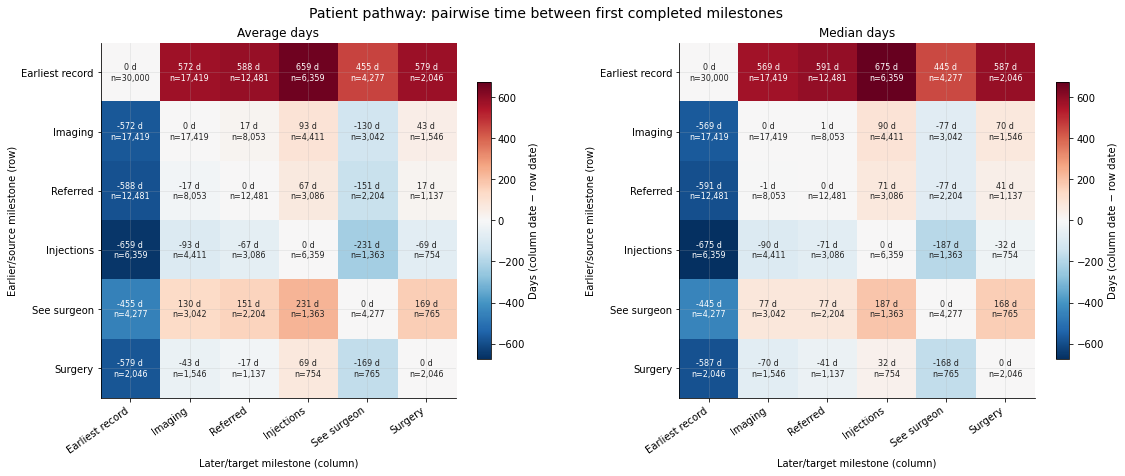

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), constrained_layout=True)
finite_values = np.concatenate([mean_days.to_numpy().ravel(), median_days.to_numpy().ravel()])
limit = np.nanmax(np.abs(finite_values))
for ax, matrix, title in zip(axes, [mean_days, median_days], ['Average days', 'Median days']):
    im = ax.imshow(matrix, cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_xticks(range(len(STAGES)), STAGES, rotation=35, ha='right')
    ax.set_yticks(range(len(STAGES)), STAGES)
    ax.set_xlabel('Later/target milestone (column)')
    ax.set_ylabel('Earlier/source milestone (row)')
    ax.set_title(title)
    for i in range(len(STAGES)):
        for j in range(len(STAGES)):
            value, n = matrix.iat[i, j], pair_counts.iat[i, j]
            if pd.notna(value):
                color = 'white' if abs(value) > .55 * limit else '#222'
                ax.text(j, i, f'{value:,.0f} d\nn={n:,}', ha='center', va='center', fontsize=8, color=color)
    fig.colorbar(im, ax=ax, shrink=.78, label='Days (column date − row date)')
fig.suptitle('Patient pathway: pairwise time between first completed milestones', fontsize=14)
plt.show()

# Part I: Birth year  *(source: patients)*
Distribution of `birth_year` in the patients table, and the implied age used as a feature (`age = 2026 - birth_year`).

30,000 patients, 0 missing birth_year, range 1900-1977
implied age (2026 - birth_year): {'count': 30000.0, 'mean': 71.2, 'std': 8.4, 'min': 49.0, '25%': 65.0, '50%': 71.0, '75%': 77.0, 'max': 126.0}


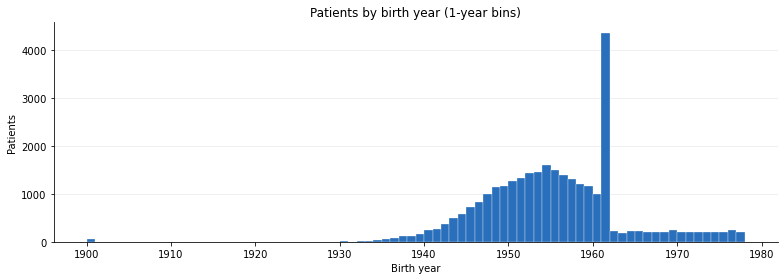

birth_year,1900,1930,1931,1932,1933,1934,1935,1936,1937,1938,1939,1940,1941,1942,1943
patients,63,15,4,22,25,29,58,69,111,131,166,246,275,382,490


In [26]:
pts = pd.read_csv('../data/meridian_health_patients.csv', dtype={'patient_token': str, 'sex': str})
by = pts.birth_year
print(f'{len(by):,} patients, {by.isna().sum()} missing birth_year, range {by.min()}-{by.max()}')
print('implied age (2026 - birth_year):', (2026 - by).describe().round(1).to_dict())

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(by, bins=range(by.min(), by.max() + 2), color=BLUE, edgecolor='white', linewidth=.3)
ax.set(title='Patients by birth year (1-year bins)', xlabel='Birth year', ylabel='Patients')
ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

by.value_counts().sort_index().rename('patients').rename_axis('birth_year').head(15).to_frame().T

## Surgery rate by birth year  *(source: patients, encounters, claims)*
Share of **all** patients-table patients (not the 1:1 sampled splits) with any surgery code (22630, 22633, 63030, 63047) in encounters or claims, any status, the same definition as `assignment/splits.py`. Birth years with fewer than 30 patients are greyed out because their rates are noisy.

2,597 of 30,000 patients with a surgery code (8.7%)


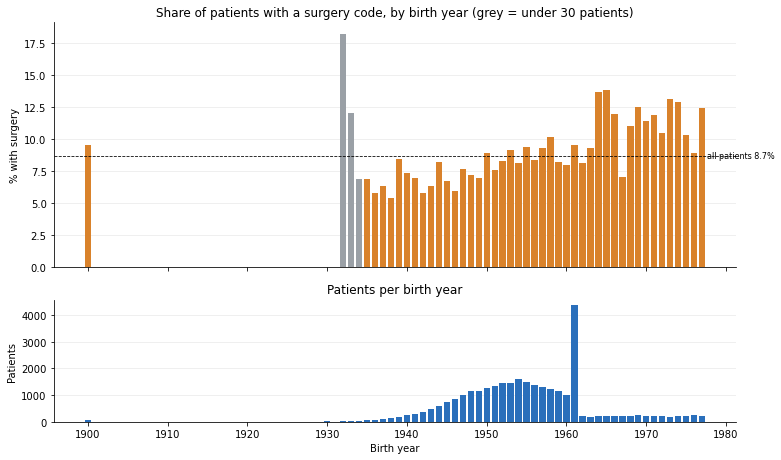

,patients,pct_surgery
birth_year,,
1900 (placeholder),63,9.5
1901-1950,8745,7.2
1951-1955,7332,8.5
1956-1960,6083,8.8
1961 (spike),4367,9.5
1962-1969,1726,11.0
1970-1977,1684,11.3


,patients,surgery,pct_surgery
birth_year,,,
1900,63,6,9.5
1930,15,0,0.0
1931,4,0,0.0
1932,22,4,18.2
1933,25,3,12.0
1934,29,2,6.9
1935,58,4,6.9
1936,69,4,5.8
1937,111,7,6.3


In [27]:
SURG = ['22630', '22633', '63030', '63047']
enc_s = pd.read_csv('../data/meridian_health_encounters.csv', usecols=['patient_token', 'event_code'], dtype=str)
clm_s = pd.read_csv('../data/data_web_claims.csv', usecols=['patient_token', 'code_system', 'code'], dtype=str)
surgery_pts = (set(enc_s.loc[enc_s.event_code.isin(SURG), 'patient_token'])
               | set(clm_s.loc[(clm_s.code_system == 'CPT') & clm_s.code.isin(SURG), 'patient_token']))

pts['surgery'] = pts.patient_token.isin(surgery_pts)
by_year = (pts.groupby('birth_year').agg(patients=('surgery', 'size'), surgery=('surgery', 'sum'))
           .assign(pct_surgery=lambda d: d.surgery / d.patients * 100))
overall = pts.surgery.mean() * 100
print(f'{pts.surgery.sum():,} of {len(pts):,} patients with a surgery code ({overall:.1f}%)')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
small = by_year.patients < 30
ax1.bar(by_year.index, by_year.pct_surgery, color=np.where(small, GRAY, ORANGE), width=.8)
ax1.axhline(overall, color='black', lw=.8, ls='--')
ax1.text(by_year.index.max() + .6, overall, f'all patients {overall:.1f}%', va='center', fontsize=8)
ax1.set(title='Share of patients with a surgery code, by birth year (grey = under 30 patients)', ylabel='% with surgery')
ax2.bar(by_year.index, by_year.patients, color=BLUE, width=.8)
ax2.set(title='Patients per birth year', xlabel='Birth year', ylabel='Patients')
for a in (ax1, ax2):
    a.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

groups = pd.cut(pts.birth_year, [0, 1900, 1950, 1955, 1960, 1961, 1969, 2000],
                labels=['1900 (placeholder)', '1901-1950', '1951-1955', '1956-1960', '1961 (spike)', '1962-1969', '1970-1977'])
display(pts.groupby(groups, observed=True).surgery.agg(patients='size', pct_surgery=lambda s: round(s.mean() * 100, 1)))
by_year.round(1)

# Part J: Outreach timing relative to surgery  *(sources: outreach, encounters, claims)*
For patients with surgery: how long before their **first surgery date** did Meridian first try to reach them? Surgery date = earliest date of any surgery code (22630, 22633, 63030, 63047), any status, in encounters or claims, the same definition as `assignment/splits.py`. `days_before_surgery` = first surgery date − outreach attempt date, so positive means the attempt came **before** surgery.

Outreach only ran from 2024-07-11 to 2026-03-13, so rates of "contacted before surgery" are computed over surgeries on or after the first outreach date. Earlier surgeries could not have been preceded by outreach.

In [28]:
out = pd.read_csv('../data/meridian_health_outreach.csv', parse_dates=['timestamp'])
out['date'] = out.timestamp.dt.normalize()
enc_d = pd.read_csv('../data/meridian_health_encounters.csv', usecols=['patient_token', 'event_date', 'event_code'], dtype=str, parse_dates=['event_date'])
clm_d = pd.read_csv('../data/data_web_claims.csv', usecols=['patient_token', 'service_date', 'code_system', 'code'], dtype=str, parse_dates=['service_date'])
surg_dates = pd.concat([
    enc_d.loc[enc_d.event_code.isin(SURG), ['patient_token', 'event_date']].rename(columns={'event_date': 'date'}),
    clm_d.loc[(clm_d.code_system == 'CPT') & clm_d.code.isin(SURG), ['patient_token', 'service_date']].rename(columns={'service_date': 'date'}),
])
first_surgery = surg_dates.groupby('patient_token').date.min().rename('first_surgery')
outreach_start, outreach_end = out.date.min(), out.date.max()

att = out.merge(first_surgery, on='patient_token')
att['days_before_surgery'] = (att.first_surgery - att.date).dt.days
per_pt = att.groupby('patient_token').agg(
    program=('program', 'first'), first_surgery=('first_surgery', 'first'),
    first_attempt_days=('days_before_surgery', 'max'),        # earliest attempt = largest days before
    attempts=('days_before_surgery', 'size'),
    attempts_before=('days_before_surgery', lambda d: (d > 0).sum()),
)
per_pt['timing'] = np.select([per_pt.attempts_before == per_pt.attempts, per_pt.attempts_before == 0],
                             ['all before surgery', 'all on/after surgery'], 'before and after')

eligible = first_surgery[first_surgery >= outreach_start]
contacted = per_pt.index.intersection(eligible.index)
before = per_pt.loc[contacted].query('attempts_before > 0').index
print(f'{len(first_surgery):,} surgery patients; {len(eligible):,} with first surgery on/after first outreach ({outreach_start.date()})')
print(f'  ever contacted: {len(contacted):,} ({len(contacted)/len(eligible):.1%}); contacted before surgery: {len(before):,} ({len(before)/len(eligible):.1%})')
print(f'all {len(per_pt):,} surgery patients with any outreach, by timing:'); display(per_pt.timing.value_counts().to_frame('patients'))

2,597 surgery patients; 2,033 with first surgery on/after first outreach (2024-07-11)
  ever contacted: 987 (48.5%); contacted before surgery: 501 (24.6%)
all 1,259 surgery patients with any outreach, by timing:


,patients
all on/after surgery,758
all before surgery,474
before and after,27


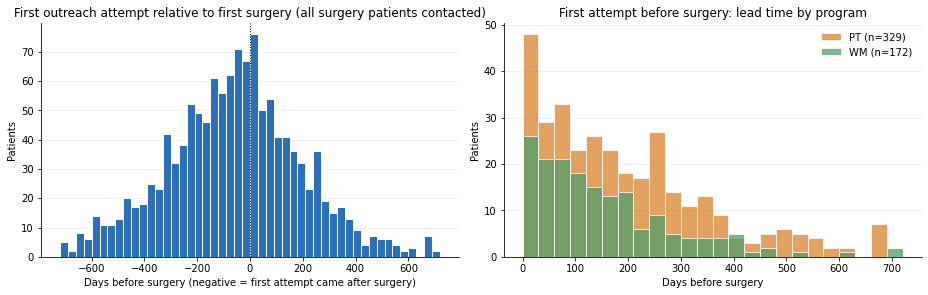

Lead time (days) from first outreach attempt to first surgery, patients first contacted before surgery:


,count,mean,std,min,10%,25%,50%,75%,90%,max
program,,,,,,,,,,
PT,329.0,193.0,162.0,1.0,22.0,62.0,153.0,273.0,421.0,689.0
WM,172.0,155.0,136.0,1.0,19.0,54.0,118.0,218.0,340.0,702.0
all,501.0,180.0,155.0,1.0,22.0,60.0,141.0,260.0,386.0,702.0


program,PT,WM,All
lead time,,,
1-30 d,51,27,78
31-90 d,60,42,102
91-180 d,71,46,117
181-365 d,101,42,143
>1 year,46,15,61
All,329,172,501


In [29]:
first_before = per_pt[per_pt.first_attempt_days > 0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.arange(-720, 721, 30)
axes[0].hist(per_pt.first_attempt_days, bins=bins, color=BLUE, edgecolor='white')
axes[0].axvline(0, color='black', lw=1, ls=':')
axes[0].set(title='First outreach attempt relative to first surgery (all surgery patients contacted)',
            xlabel='Days before surgery (negative = first attempt came after surgery)', ylabel='Patients')
for prog, colr in [('PT', ORANGE), ('WM', '#4f9d69')]:
    d = first_before.loc[first_before.program == prog, 'first_attempt_days']
    axes[1].hist(d, bins=np.arange(0, 721, 30), color=colr, alpha=.75, edgecolor='white', label=f'{prog} (n={len(d):,})')
axes[1].set(title='First attempt before surgery: lead time by program', xlabel='Days before surgery', ylabel='Patients')
axes[1].legend(frameon=False)
for a in axes:
    a.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

lead = first_before.groupby('program').first_attempt_days.describe(percentiles=[.1, .25, .5, .75, .9]).round(0)
lead.loc['all'] = first_before.first_attempt_days.describe(percentiles=[.1, .25, .5, .75, .9]).round(0)
print('Lead time (days) from first outreach attempt to first surgery, patients first contacted before surgery:')
display(lead)
bands = pd.cut(first_before.first_attempt_days, [0, 30, 90, 180, 365, 10_000], labels=['1-30 d', '31-90 d', '91-180 d', '181-365 d', '>1 year'])
display(pd.crosstab(bands, first_before.program, margins=True).rename_axis('lead time'))

# Part K: Outreach volume and success by quarter  *(sources: outreach, enrollments)*
Attempts per calendar quarter, and how many were **successful**: the attempt result was `Connected` (a live phone conversation) **and** the patient enrolled in the *same program* the attempt was for within 90 days after it. Email `Opened` and delivered-only SMS or email don't count as connected.

For context the table also shows each part separately: connected attempts, and attempts followed by enrollment within 90 days whatever the result. Quarters with no outreach are shown as zero; campaigns ran every other quarter. Enrollment after a connected call is not proof the call *caused* it: there is no control group, and 42% of enrollees were never contacted.

38,464 attempts; 6,441 connected; 1,701 successful (4.4% of attempts, 26.4% of connected calls)


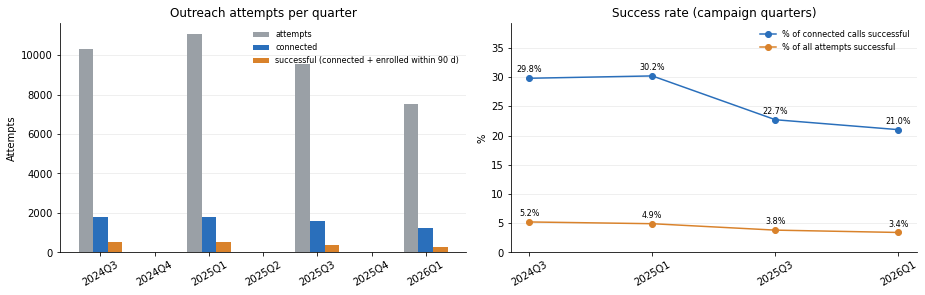

,attempts,patients,connected,enrolled_90d,successful,patients_successful,pct_attempts_successful,pct_connected_successful
2024Q3,10321,2966,1788,2239,532,334,5.2,29.8
2024Q4,0,0,0,0,0,0,NaN,NaN
2025Q1,11076,3183,1806,2322,545,342,4.9,30.2
2025Q2,0,0,0,0,0,0,NaN,NaN
2025Q3,9529,2737,1606,1778,364,237,3.8,22.7
2025Q4,0,0,0,0,0,0,NaN,NaN
2026Q1,7538,2189,1241,1257,260,165,3.4,21.0


In [30]:
enr = pd.read_csv('../data/meridian_health_enrollments.csv', parse_dates=['enrollment_date'])
o = out.copy()
o['quarter'] = o.timestamp.dt.to_period('Q')
o['connected'] = o.attempt_result.eq('Connected')

# enrolled in the same program within 90 days after the attempt
m = o[['patient_token', 'program', 'date']].reset_index().merge(enr, on=['patient_token', 'program'], how='left')
m['gap'] = (m.enrollment_date - m.date).dt.days
o['enrolled_90d'] = m.assign(hit=m.gap.between(0, 90)).groupby('index').hit.any().reindex(o.index, fill_value=False)
o['successful'] = o.connected & o.enrolled_90d

quarters = pd.period_range(o.quarter.min(), o.quarter.max(), freq='Q')
by_q = (o.groupby('quarter')
        .agg(attempts=('patient_token', 'size'), patients=('patient_token', 'nunique'), connected=('connected', 'sum'),
             enrolled_90d=('enrolled_90d', 'sum'), successful=('successful', 'sum'))
        .reindex(quarters, fill_value=0))
by_q['patients_successful'] = o[o.successful].groupby('quarter').patient_token.nunique().reindex(quarters, fill_value=0)
by_q['pct_attempts_successful'] = (by_q.successful / by_q.attempts * 100).round(1)
by_q['pct_connected_successful'] = (by_q.successful / by_q.connected * 100).round(1)
by_q.index = by_q.index.astype(str)
total = by_q.sum(numeric_only=True)
print(f"{int(total.attempts):,} attempts; {int(total.connected):,} connected; {int(total.successful):,} successful "
      f"({total.successful / total.attempts:.1%} of attempts, {total.successful / total.connected:.1%} of connected calls)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(by_q)); w = .27
for k, (col, colr, lab) in enumerate([('attempts', GRAY, 'attempts'), ('connected', BLUE, 'connected'),
                                      ('successful', ORANGE, 'successful (connected + enrolled within 90 d)')]):
    ax1.bar(x + (k - 1) * w, by_q[col], width=w, color=colr, label=lab)
ax1.set_xticks(x, by_q.index, rotation=30)
ax1.set(title='Outreach attempts per quarter', ylabel='Attempts'); ax1.legend(frameon=False, fontsize=8)
camp = by_q[by_q.attempts > 0]
ax2.plot(camp.index, camp.pct_connected_successful, marker='o', color=BLUE, label='% of connected calls successful')
ax2.plot(camp.index, camp.pct_attempts_successful, marker='o', color=ORANGE, label='% of all attempts successful')
for a, col in [(ax2, 'pct_connected_successful'), (ax2, 'pct_attempts_successful')]:
    for xi, v in zip(camp.index, camp[col]):
        a.annotate(f'{v:.1f}%', (xi, v), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=8)
ax2.set(title='Success rate (campaign quarters)', ylabel='%', ylim=(0, camp.pct_connected_successful.max() * 1.3))
ax2.tick_params(axis='x', rotation=30); ax2.legend(frameon=False, fontsize=8)
for a in (ax1, ax2):
    a.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
display(by_q)

In [31]:
prog_q = (o.groupby([o.quarter.astype(str), 'program'])
          .agg(attempts=('patient_token', 'size'), connected=('connected', 'sum'), successful=('successful', 'sum'))
          .assign(pct_attempts_successful=lambda d: (d.successful / d.attempts * 100).round(1),
                  pct_connected_successful=lambda d: (d.successful / d.connected * 100).round(1)))
display(prog_q)
# for comparison: how often do non-connected attempts precede enrollment?
print('% of attempts followed by enrollment within 90 d, by whether the call connected:')
display((o.groupby(['program', 'connected']).enrolled_90d.mean() * 100).round(1).unstack())

attempts  connected  successful  pct_attempts_successful  \
quarter program                                                             
2024Q3  PT           7181       1210         422                      5.9   
        WM           3140        578         110                      3.5   
2025Q1  PT           7913       1265         432                      5.5   
        WM           3163        541         113                      3.6   
2025Q3  PT           6700       1150         298                      4.4   
        WM           2829        456          66                      2.3   
2026Q1  PT           5106        835         216                      4.2   
        WM           2432        406          44                      1.8   

                 pct_connected_successful  
quarter program                            
2024Q3  PT                           34.9  
        WM                           19.0  
2025Q1  PT                           34.2  
        WM                           20.9  
2025Q3  PT                           25.9  
        WM                           14.5  
2026Q1  PT                           25.9  
        WM                           10.8

% of attempts followed by enrollment within 90 d, by whether the call connected:


connected,False,True
program,,
PT,19.8,30.7
WM,15.3,16.8


## Patients outreached, contacted and successful by quarter
Unique patients per calendar quarter, same definitions as above:
- **Outreached:** any attempt that quarter.
- **Contacted:** at least one `Connected` call that quarter.
- **Successful:** a `Connected` call that quarter and enrollment in that program within 90 days.

Rates are out of all patients outreached that quarter. Quarters without outreach are shown as zero. Dashed lines are the **mean over the four campaign quarters**, and the table below sets a +5%-over-mean target.

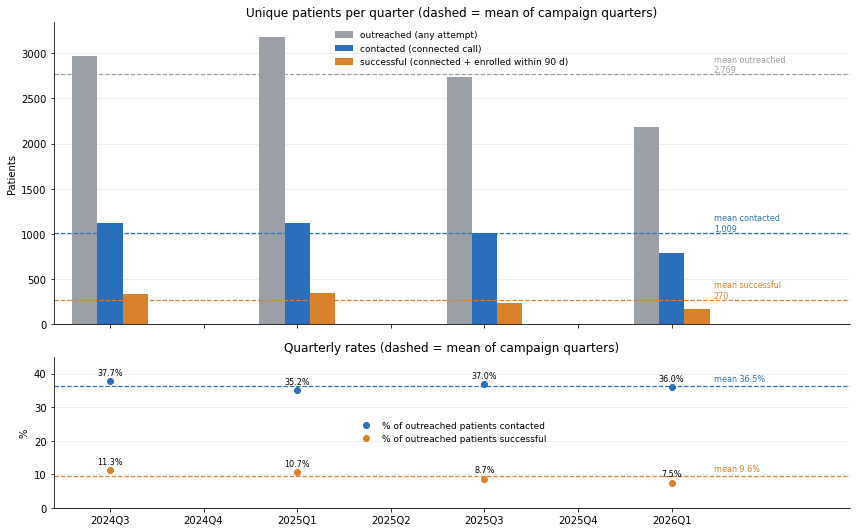

,outreached,contacted,successful,pct_contacted,pct_successful
2024Q3,2966,1117,334,37.7,11.3
2024Q4,0,0,0,NaN,NaN
2025Q1,3183,1119,342,35.2,10.7
2025Q2,0,0,0,NaN,NaN
2025Q3,2737,1013,237,37.0,8.7
2025Q4,0,0,0,NaN,NaN
2026Q1,2189,787,165,36.0,7.5


mean successful patients per campaign quarter: 269.5 -> +5% target: 283


,outreach volume needed,success rate needed (%)
keep latest success rate (7.5%),3773,7.5
"keep latest volume (2,189)",2189,12.9
"mean volume (2,769)",2769,10.2


In [32]:
by_q2 = pd.DataFrame({
    'outreached': o.groupby('quarter').patient_token.nunique(),
    'contacted': o[o.connected].groupby('quarter').patient_token.nunique(),
    'successful': o[o.successful].groupby('quarter').patient_token.nunique(),
}).reindex(quarters, fill_value=0).fillna(0).astype(int)
by_q2['pct_contacted'] = (by_q2.contacted / by_q2.outreached * 100).round(1)
by_q2['pct_successful'] = (by_q2.successful / by_q2.outreached * 100).round(1)
by_q2.index = by_q2.index.astype(str)
camp = by_q2[by_q2.outreached > 0]
mean = camp.mean()

SERIES = [('outreached', GRAY, 'outreached (any attempt)'), ('contacted', BLUE, 'contacted (connected call)'),
          ('successful', ORANGE, 'successful (connected + enrolled within 90 d)')]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
x = np.arange(len(by_q2)); w = .27
for k, (col, colr, lab) in enumerate(SERIES):
    ax1.bar(x + (k - 1) * w, by_q2[col], width=w, color=colr, label=lab)
    ax1.axhline(mean[col], color=colr, lw=1.2, ls='--')
    ax1.text(x[-1] + .45, mean[col], f'mean {col}\n{mean[col]:,.0f}', va='bottom', fontsize=8, color=colr)
ax1.set(title='Unique patients per quarter (dashed = mean of campaign quarters)', ylabel='Patients')
ax1.legend(frameon=False, fontsize=9, loc='upper center')
for col, colr, lab in [('pct_contacted', BLUE, '% of outreached patients contacted'),
                       ('pct_successful', ORANGE, '% of outreached patients successful')]:
    ax2.plot(x, by_q2[col].where(by_q2.outreached > 0), marker='o', ls='none', color=colr, label=lab)
    ax2.axhline(mean[col], color=colr, lw=1.2, ls='--')
    ax2.text(x[-1] + .45, mean[col] + .8, f'mean {mean[col]:.1f}%', va='bottom', fontsize=8, color=colr)
    for xi, v in zip(x, by_q2[col]):
        if v > 0:
            ax2.annotate(f'{v:.1f}%', (xi, v), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=8)
ax2.set(title='Quarterly rates (dashed = mean of campaign quarters)', ylabel='%', ylim=(0, 45))
ax2.legend(frameon=False, fontsize=9, loc='center')
ax2.set_xticks(x, by_q2.index)
ax2.set_xlim(-.6, len(x) + .9)
for a in (ax1, ax2):
    a.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
display(by_q2)

# +5% over the campaign-quarter mean, and what reaching it takes
target = int(np.ceil(mean.successful * 1.05))
latest = camp.iloc[-1]
print(f"mean successful patients per campaign quarter: {mean.successful:.1f} -> +5% target: {target}")
display(pd.DataFrame({
    'outreach volume needed': [round(target / (latest.pct_successful / 100)), int(latest.outreached), round(mean.outreached)],
    'success rate needed (%)': [latest.pct_successful, round(target / latest.outreached * 100, 1), round(target / mean.outreached * 100, 1)],
}, index=[f'keep latest success rate ({latest.pct_successful}%)', f'keep latest volume ({latest.outreached:,.0f})',
          f'mean volume ({mean.outreached:,.0f})']))